In [1]:
# =========================================================
# CELL 1 & 2: AUTO-MERGE SEMUA EXCEL & CSV (BEBAS NAMA FILE)
# =========================================================
!pip install -q openpyxl transformers datasets torch tqdm

import os
import glob
import re
import torch
import pandas as pd
from transformers import pipeline
from transformers.pipelines.pt_utils import KeyDataset
from datasets import Dataset
from tqdm.auto import tqdm

# ---------------------------------------------------------
# 1. DETEKSI SEMUA FILE EXCEL & CSV DI FOLDER KERJA COLAB
# ---------------------------------------------------------
# Jika ingin menyebut nama file secara manual, isi list di bawah ini, contoh:
# MANUAL_FILES = ["data_per_tanggal.xlsx", "data_utama.xlsx"]
# Jika dibiarkan kosong [], kode akan otomatis mengambil SEMUA Excel & CSV di Colab.
MANUAL_FILES = []

if MANUAL_FILES:
    target_files = MANUAL_FILES
else:
    all_files = glob.glob("*.xlsx") + glob.glob("*.xls") + glob.glob("*.csv")
    # Kecualikan file hasil akhir ('final') agar tidak ikut tergabung ulang
    target_files = [
        f for f in all_files
        if os.path.isfile(f) and "final" not in f.lower()
    ]

if not target_files:
    raise FileNotFoundError("❌ Tidak ada file Excel (.xlsx/.xls) atau CSV di panel Files Colab!")

print(f"📂 Ditemukan {len(target_files)} file untuk digabung: {target_files}")

df_list = []
for f in target_files:
    if f.lower().endswith((".xlsx", ".xls")):
        temp_df = pd.read_excel(f, engine="openpyxl")
    else:
        temp_df = pd.read_csv(f)

    # Deteksi otomatis nama kolom yang berisi teks berita
    possible_cols = ["text", "raw_text", "title", "judul", "berita", "content", "isi"]
    found_col = next((c for c in possible_cols if c in temp_df.columns), None)

    if not found_col:
        raise KeyError(
            f"❌ Kolom teks tidak ditemukan di '{f}'. "
            f"Kolom tersedia: {list(temp_df.columns)}"
        )

    temp_df = temp_df.rename(columns={found_col: "text"})
    df_list.append(temp_df)
    print(f"   -> Berhasil memuat '{f}' ({len(temp_df)} baris | kolom: '{found_col}')")

df = pd.concat(df_list, ignore_index=True)

# ---------------------------------------------------------
# 2. PEMBERSIHAN TEKS & HAPUS DUPLIKAT LINTAS FILE
# ---------------------------------------------------------
def clean_text(text: str) -> str:
    """Standardisasi pembersihan teks untuk training dan inference Streamlit."""
    text = str(text).lower()
    text = re.sub(r"\s+-\s+[^-]+$", "", text)  # Hapus nama media di belakang judul
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df = df.dropna(subset=["text"]).reset_index(drop=True)
df["clean_text"] = df["text"].apply(clean_text)

total_sebelum = len(df)
df = df.drop_duplicates(subset=["clean_text"])
df = df[df["clean_text"].str.len() > 10].reset_index(drop=True)
print(f"\n🧹 Data bersih unik: {len(df)} baris (Dibuang {total_sebelum - len(df)} duplikat/noise)\n")

# ---------------------------------------------------------
# 3. PELABELAN OTOMATIS CEPAT (GPU BATCH PROCESSING)
# ---------------------------------------------------------
device_id = 0 if torch.cuda.is_available() else -1
print(f"⚙️ Memuat model Zero-Shot di device: {'GPU (T4)' if device_id == 0 else 'CPU'}")

classifier = pipeline(
    "zero-shot-classification",
    model="MoritzLaurer/mDeBERTa-v3-base-mnli-xnli",
    device=device_id
)

CANDIDATE_LABELS = [
    "berita reguler aman dan netral",
    "ujaran kebencian konflik sosial dan kerusuhan",
    "propaganda hoaks dan disinformasi terstruktur"
]

LABEL_TO_ID = {
    "berita reguler aman dan netral": 0,
    "ujaran kebencian konflik sosial dan kerusuhan": 1,
    "propaganda hoaks dan disinformasi terstruktur": 2
}

hf_dataset = Dataset.from_pandas(df[["clean_text"]])
predicted_labels = []

print(f"🚀 Melabeli {len(df)} data dengan batch processing...")
for out in tqdm(classifier(KeyDataset(hf_dataset, "clean_text"), CANDIDATE_LABELS, batch_size=32), total=len(df)):
    top_label = out["labels"][0]
    predicted_labels.append(LABEL_TO_ID[top_label])

df["label"] = predicted_labels

# Simpan hasil final untuk tahap training BiLSTM & Dashboard Streamlit
df.to_csv("dataset_cyber_alerts_LATEST.csv", index=False)
print("\n✅ Selesai! Disimpan ke 'dataset_cyber_alerts_LATEST.csv'")
print("Distribusi Kelas (0: Aman, 1: Konflik, 2: Propaganda):")
print(df["label"].value_counts())


📂 Ditemukan 1 file untuk digabung: ['dataset_cyber_alerts_LATEST.csv']
   -> Berhasil memuat 'dataset_cyber_alerts_LATEST.csv' (9981 baris | kolom: 'text')

🧹 Data bersih unik: 9941 baris (Dibuang 40 duplikat/noise)

⚙️ Memuat model Zero-Shot di device: GPU (T4)


config.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

... (6 outputs left out)

special_tokens_map.json:   0%|          | 0.00/286 [00:00<?, ?B/s]

🚀 Melabeli 9941 data dengan batch processing...


  0%|          | 0/9941 [00:00<?, ?it/s]


✅ Selesai! Disimpan ke 'dataset_cyber_alerts_LATEST.csv'
Distribusi Kelas (0: Aman, 1: Konflik, 2: Propaganda):
label
2    6638
1    3011
0     292
Name: count, dtype: int64


In [2]:
# =========================================================
# CELL 3 & 4: SPLIT, CLASS WEIGHT, TRAINING BiLSTM & EXPORT
# =========================================================
import json
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Bidirectional, LSTM, Dropout, Dense
from tensorflow.keras.callbacks import EarlyStopping

# 1. Baca dari file FINAL yang sudah berlabel
df = pd.read_csv('dataset_cyber_alerts_LATEST.csv').dropna(subset=['clean_text', 'label'])
df['clean_text'] = df['clean_text'].astype(str)
df['label'] = df['label'].astype(int)

MAX_WORDS = 5000
MAX_LEN = 50

# 2. Split Data TERLEBIH DAHULU (Mencegah Data Leakage pada Tokenizer)
train_texts, test_texts, y_train_raw, y_test_raw = train_test_split(
    df['clean_text'],
    df['label'],
    test_size=0.2,
    random_state=42,
    stratify=df['label']
)

# 3. Latih Tokenizer HANYA pada data training & SIMPAN KE FILE JSON
tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token='<OOV>')
tokenizer.fit_on_texts(train_texts)

with open('tokenizer_cyber.json', 'w', encoding='utf-8') as f:
    f.write(tokenizer.to_json())
print("✅ Kamus Tokenizer berhasil disimpan ke 'tokenizer_cyber.json'")

# 4. Konversi Teks ke Sekuens Angka & Padding
X_train = pad_sequences(tokenizer.texts_to_sequences(train_texts), maxlen=MAX_LEN, padding='post', truncating='post')
X_test = pad_sequences(tokenizer.texts_to_sequences(test_texts), maxlen=MAX_LEN, padding='post', truncating='post')

y_train = tf.keras.utils.to_categorical(y_train_raw, num_classes=3)
y_test = tf.keras.utils.to_categorical(y_test_raw, num_classes=3)

# 5. Hitung Bobot Kelas Otomatis (Mengatasi jumlah data per kelas yang tidak seimbang)
classes = np.unique(y_train_raw)
weights = compute_class_weight(class_weight='balanced', classes=classes, y=y_train_raw)
class_weight_dict = dict(zip(classes, weights))
print(f"⚖️ Bobot Kelas Otomatis: {class_weight_dict}")

# 6. Arsitektur BiLSTM
model = Sequential([
    Embedding(input_dim=MAX_WORDS, output_dim=128),
    Bidirectional(LSTM(64, return_sequences=True)),
    Dropout(0.3),
    Bidirectional(LSTM(32)),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dense(3, activation='softmax')
])

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_test, y_test),
    class_weight=class_weight_dict,
    callbacks=[early_stop],
    verbose=1
)

# 7. Simpan Model Utama & Konfigurasi untuk Aplikasi Streamlit
model.save('model_cyber_bilstm.keras')

config_data = {
    "max_words": MAX_WORDS,
    "max_len": MAX_LEN,
    "label_map": {
        "0": "Aman/Netral",
        "1": "Potensi Konflik",
        "2": "Propaganda/Disinformasi"
    }
}
with open('model_config.json', 'w', encoding='utf-8') as f:
    json.dump(config_data, f, indent=4)

print("✅ Model ('model_cyber_bilstm.keras') & Config ('model_config.json') berhasil disimpan!")


✅ Kamus Tokenizer berhasil disimpan ke 'tokenizer_cyber.json'
⚖️ Bobot Kelas Otomatis: {np.int64(0): np.float64(11.327635327635328), np.int64(1): np.float64(1.1007751937984496), np.int64(2): np.float64(0.49918392969240427)}
Epoch 1/20
249/249 ━━━━━━━━━━━━━━━━━━━━ 29s 40ms/step - accuracy: 0.5908 - loss: 0.9457 - val_accuracy: 0.7079 - val_loss: 0.6876
Epoch 2/20
249/249 ━━━━━━━━━━━━━━━━━━━━ 12s 48ms/step - accuracy: 0.7923 - loss: 0.5434 - val_accuracy: 0.6843 - val_loss: 0.7713
Epoch 3/20
249/249 ━━━━━━━━━━━━━━━━━━━━ 12s 48ms/step - accuracy: 0.8706 - loss: 0.3199 - val_accuracy: 0.7733 - val_loss: 0.6032
Epoch 4/20
249/249 ━━━━━━━━━━━━━━━━━━━━ 7s 26ms/step - accuracy: 0.9106 - loss: 0.1943 - val_accuracy: 0.7391 - val_loss: 0.8350
Epoch 5/20
249/249 ━━━━━━━━━━━━━━━━━━━━ 10s 41ms/step - accuracy: 0.9340 - loss: 0.1512 - val_accuracy: 0.7617 - val_loss: 0.7691
Epoch 6/20
249/249 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - accuracy: 0.9574 - loss: 0.0927 - val_accuracy: 0.7647 - val_loss: 0.903

=== EVALUASI MODEL PEMBANDING (TF-IDF + LOGISTIC REGRESSION) ===
✅ Model cadangan TF-IDF & LogisticRegression disimpan (.joblib)


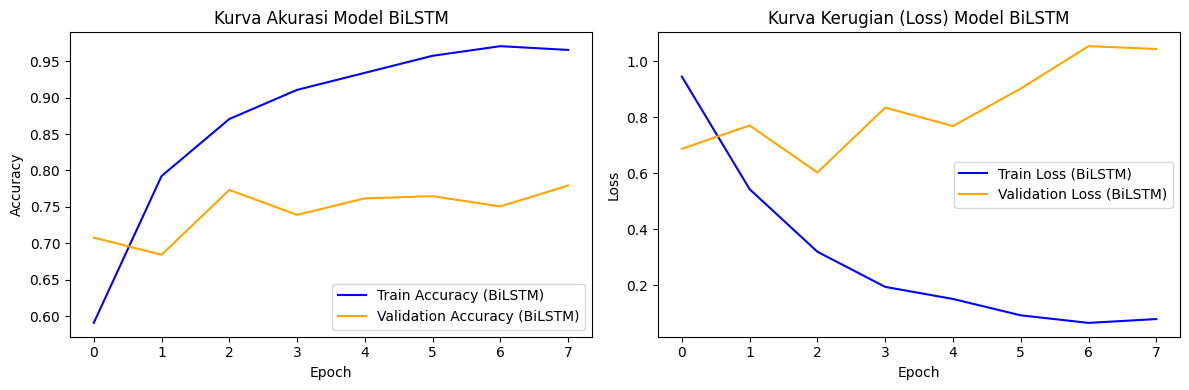


-> AKURASI MODEL TF-IDF + LOGREG: 78.78%

Detail Klasifikasi Performa Tiap Kelas:
                         precision    recall  f1-score   support

            Aman/Netral       0.19      0.34      0.24        58
        Potensi Konflik       0.71      0.77      0.74       603
Propaganda/Disinformasi       0.88      0.81      0.85      1328

               accuracy                           0.79      1989
              macro avg       0.59      0.64      0.61      1989
           weighted avg       0.81      0.79      0.80      1989



In [3]:
# =========================================================
# CELL 5: EVALUASI, VISUALISASI & SIMPAN MODEL CADANGAN (TF-IDF)
# =========================================================
import joblib
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

print("=== EVALUASI MODEL PEMBANDING (TF-IDF + LOGISTIC REGRESSION) ===")

df_train, df_test = train_test_split(
    df, test_size=0.2, random_state=42, stratify=df['label']
)

vectorizer = TfidfVectorizer(max_features=3000, ngram_range=(1, 2))
X_train_ml = vectorizer.fit_transform(df_train['clean_text'])
X_test_ml = vectorizer.transform(df_test['clean_text'])

model_ml = LogisticRegression(class_weight='balanced', C=2.0, max_iter=1000, random_state=42)
model_ml.fit(X_train_ml, df_train['label'])

y_pred_ml = model_ml.predict(X_test_ml)
akurasi_final = accuracy_score(df_test['label'], y_pred_ml)

# Simpan artefak model cadangan (sangat ringan & cepat untuk Streamlit)
joblib.dump(vectorizer, 'tfidf_vectorizer.joblib')
joblib.dump(model_ml, 'model_cyber_logreg.joblib')
print("✅ Model cadangan TF-IDF & LogisticRegression disimpan (.joblib)")

# Visualisasi Kurva Training BiLSTM
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy (BiLSTM)', color='blue')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy (BiLSTM)', color='orange')
plt.title('Kurva Akurasi Model BiLSTM')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss (BiLSTM)', color='blue')
plt.plot(history.history['val_loss'], label='Validation Loss (BiLSTM)', color='orange')
plt.title('Kurva Kerugian (Loss) Model BiLSTM')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

# Laporan Klasifikasi sesuai 3 Kelas Cognitive Defense
TARGET_CLASSES = ['Aman/Netral', 'Potensi Konflik', 'Propaganda/Disinformasi']
print("\n" + "=" * 55)
print(f"-> AKURASI MODEL TF-IDF + LOGREG: {akurasi_final * 100:.2f}%")
print("=" * 55)
print("\nDetail Klasifikasi Performa Tiap Kelas:")
print(classification_report(df_test['label'], y_pred_ml, target_names=TARGET_CLASSES))


In [4]:
# =========================================================
# CELL SINKRONISASI: MEMUAT ULANG MODEL TERPINTAR HASIL TRAINING
# =========================================================
from tensorflow.keras.models import load_model

print("Sedang menyuntikkan file bobot model terbaru ke memori Colab...")

try:
    # Memaksa memori mengabaikan variabel lama dan memuat file .keras hasil re-training data melimpah
    model = load_model('model_cyber_bilstm.keras')
    print("\n" + "="*60)
    print("-> SINKRONISASI SUKSES! Otak Model BiLSTM Baru Berhasil Aktif.")
    print("-> Sekarang, silakan jalankan kembali CELL 8 di bawahnya!")
    print("="*60)
except Exception as e:
    print(f"\n[Error] Gagal membaca berkas model: {str(e)}")
    print("Pastikan Anda sudah menjalankan CELL 6 (Model.fit) sampai selesai menyimpan file .keras!")

Sedang menyuntikkan file bobot model terbaru ke memori Colab...

-> SINKRONISASI SUKSES! Otak Model BiLSTM Baru Berhasil Aktif.
-> Sekarang, silakan jalankan kembali CELL 8 di bawahnya!


In [5]:
# =========================================================
# CELL 8: CONTOH INFERENCE YANG KONSISTEN UNTUK STREAMLIT
# =========================================================
import json
import numpy as np
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.text import tokenizer_from_json
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Muat Model & Tokenizer yang sudah disimpan
loaded_model = load_model('model_cyber_bilstm.keras')
with open('tokenizer_cyber.json', 'r', encoding='utf-8') as f:
    loaded_tokenizer = tokenizer_from_json(f.read())

LABEL_MAP = {
    0: "🟢 AMAN / NETRAL (Berita Reguler)",
    1: "🟡 POTENSI KONFLIK (Ujaran Kebencian / Polarisasi)",
    2: "🔴 PROPAGANDA / DISINFORMASI (Ancaman Siber Sosial)"
}

def predict_article(title_text: str) -> dict:
    cleaned = clean_text(title_text)
    seq = loaded_tokenizer.texts_to_sequences([cleaned])
    padded = pad_sequences(seq, maxlen=50, padding='post', truncating='post')

    probs = loaded_model.predict(padded, verbose=0)[0]
    pred_idx = int(np.argmax(probs))

    return {
        "clean_text": cleaned,
        "status": LABEL_MAP[pred_idx],
        "confidence": float(probs[pred_idx] * 100),
        "probabilities": {
            "Aman": round(float(probs[0] * 100), 2),
            "Konflik": round(float(probs[1] * 100), 2),
            "Propaganda": round(float(probs[2] * 100), 2)
        }
    }

# Uji coba prediksi
sample = "Sebarkan! Beredar kabar hoaks ribuan pasukan asing menyusup ke perbatasan"
print(predict_article(sample))


{'clean_text': 'sebarkan beredar kabar hoaks ribuan pasukan asing menyusup ke perbatasan', 'status': '🔴 PROPAGANDA / DISINFORMASI (Ancaman Siber Sosial)', 'confidence': 94.8613052368164, 'probabilities': {'Aman': 0.86, 'Konflik': 4.27, 'Propaganda': 94.86}}


In [1]:
# =========================================================
# CELL 6: PERSIAPAN STREAMLIT & CLOUDFLARE TUNNEL
# =========================================================
!pip install -q streamlit plotly
!wget -q -O cloudflared https://github.com
!chmod +x cloudflared

print("✅ Streamlit dan Cloudflare Tunnel siap dijalankan langsung dari Notebook 2!")


✅ Streamlit dan Cloudflare Tunnel siap dijalankan langsung dari Notebook 2!


In [11]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import json
import re
import os
import requests
from bs4 import BeautifulSoup
import plotly.express as px
import plotly.graph_objects as go
import tensorflow as tf
from tensorflow.keras.preprocessing.text import tokenizer_from_json
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Konfigurasi Halaman
st.set_page_config(
    page_title="Wasabil Corefine AI-Cyber Cognitive Defense System | Command Center",
    page_icon="🛡️",
    layout="wide",
    initial_sidebar_state="expanded"
)

# 2. Custom CSS untuk Tampilan SOC Modern & Dark Glassmorphism
st.markdown("""
<style>
    .main {
        background-color: #0b0f19;
    }
    .stMetric {
        background: linear-gradient(135deg, #131b2e 0%, #1a243d 100%);
        border: 1px solid #2a3b5c;
        border-radius: 12px;
        padding: 16px 20px;
        box-shadow: 0 4px 15px rgba(0, 0, 0, 0.3);
    }
    .stMetric label {
        color: #8fa6cb !important;
        font-size: 0.9rem !important;
        font-weight: 600 !important;
    }
    .stMetric div[data-testid="stMetricValue"] {
        color: #ffffff !important;
        font-size: 1.9rem !important;
        font-weight: 700 !important;
    }
    .header-banner {
        background: linear-gradient(90deg, #0f172a 0%, #1e293b 50%, #0f172a 100%);
        border-left: 5px solid #38bdf8;
        padding: 20px 25px;
        border-radius: 10px;
        margin-bottom: 20px;
    }
    .keyword-badge {
        display: inline-block;
        background-color: #1e293b;
        color: #38bdf8;
        border: 1px solid #38bdf8;
        padding: 4px 12px;
        border-radius: 20px;
        font-size: 0.85rem;
        margin-right: 6px;
        margin-bottom: 6px;
    }
</style>
""", unsafe_allow_html=True)

# 3. Load Model & Dataset
@st.cache_resource
def load_assets():
    model = tf.keras.models.load_model('model_cyber_bilstm.keras')
    with open('tokenizer_cyber.json', 'r', encoding='utf-8') as f:
        tokenizer = tokenizer_from_json(f.read())
    return model, tokenizer

@st.cache_data
def load_dataset():
    for fname in ['dataset_cyber_final.csv', 'dataset_cyber_alerts_LATEST.csv', 'dataset_cyber_alerts.csv']:
        if os.path.exists(fname):
            df = pd.read_csv(fname)
            return df, fname
    return None, None

model, tokenizer = load_assets()
df_raw, loaded_filename = load_dataset()

LABEL_MAP = {
    0: "🟢 AMAN / NETRAL",
    1: "🟡 POTENSI KONFLIK",
    2: "🔴 PROPAGANDA / DISINFORMASI"
}

LABEL_DESC = {
    0: "Berita informatif reguler tanpa indikasi provokasi atau disinformasi.",
    1: "Mengandung narasi polarisasi, kerusuhan, atau potensi gesekan sosial.",
    2: "Terindikasi kuat sebagai narasi provokatif, klaim palsu, atau disinformasi."
}

# 4. Fungsi Utilitas NLP & Scraper
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'[^a-z0-9\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

def predict_single(text):
    cleaned = clean_text(text)
    seq = tokenizer.texts_to_sequences([cleaned])
    padded = pad_sequences(seq, maxlen=50, padding='post', truncating='post')
    probs = model.predict(padded, verbose=0)[0]
    idx = int(np.argmax(probs))

    # Ekstrak kata yang dikenali oleh kamus AI
    word_index = tokenizer.word_index
    recognized_words = [w for w in cleaned.split() if w in word_index and word_index[w] < 5000]
    return idx, probs, cleaned, recognized_words

def extract_title_from_url(url):
    headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36'}
    response = requests.get(url, headers=headers, timeout=10)
    response.raise_for_status()
    soup = BeautifulSoup(response.text, 'html.parser')
    og_title = soup.find("meta", property="og:title")
    judul = og_title["content"].strip() if (og_title and og_title.get("content")) else (soup.title.string.strip() if soup.title else None)
    if judul:
        for sep in [" - ", " | "]:
            if sep in judul:
                judul = judul.split(sep)[0].strip()
    return judul

# 5. Sidebar Filter
with st.sidebar:
    st.title("🛡️ Wasabil Corefine AI")
    st.caption("Engine: Bidirectional LSTM v2.2")
    st.divider()

    df_filtered = df_raw.copy() if df_raw is not None else None
    if df_filtered is not None:
        st.subheader("🎛️ Filter Pemantauan")
        if 'keyword' in df_filtered.columns:
            all_kw = ["Semua Topik"] + sorted(df_filtered['keyword'].dropna().unique().tolist())
            selected_kw = st.selectbox("Filter Kata Kunci:", all_kw)
            if selected_kw != "Semua Topik":
                df_filtered = df_filtered[df_filtered['keyword'] == selected_kw]

        label_col = next((c for c in ['sentiment', 'label', 'kelas', 'kategori'] if c in df_filtered.columns), None)
        if label_col:
            df_filtered['Kategori_Nama'] = df_filtered[label_col].map(LABEL_MAP).fillna(df_filtered[label_col].astype(str))

        st.info(f"Menampilkan **{len(df_filtered):,}** artikel dari total **{len(df_raw):,}** data.")

# 6. Banner Utama
st.markdown("""
<div class="header-banner">
    <h2 style="margin:0; color:#f8fafc;">🛡️ Wasabil Corefine AI – Cyber Cognitive Defense System Threat & Disinformation Intelligence</h2>
    <p style="margin:5px 0 0 0; color:#94a3b8;">Sistem Pemantauan Isu Siber & Klasifikasi Berita Real-Time Berbasis Deep Learning (BiLSTM)</p>
</div>
""", unsafe_allow_html=True)

# 7. Navigasi Utama (Tab Terpisah Agar Lebih Bersih)
menu_utama = st.tabs(["🔍 Uji Deteksi Real-Time", "📊 Dashboard Intelijen Data", "📂 Analisis Massal (CSV)"])

# === TAB 1: UJI DETEKSI REAL-TIME ===
with menu_utama[0]:
    col_in, col_out = st.columns([1.1, 1.2], gap="large")

    with col_in:
        st.subheader("Input Target Analisis")
        mode_input = st.radio("Pilih Metode Input:", ["📝 Teks Judul / Klaim", "🔗 Tautan (URL) Berita"], horizontal=True)

        teks_uji = ""
        if mode_input == "📝 Teks Judul / Klaim":
            txt = st.text_area("Masukkan judul berita:", height=130, placeholder="Contoh: Sebarkan! Beredar kabar hoaks ribuan pasukan asing...")
            if st.button("🚀 Jalankan Analisis AI", type="primary", use_container_width=True):
                if txt.strip():
                    teks_uji = txt.strip()
                else:
                    st.warning("Masukkan teks terlebih dahulu.")
        else:
            url_in = st.text_input("Tempelkan URL portal berita:", placeholder="https://detik.com...")
            if st.button("🌐 Tarik Judul & Analisis", type="primary", use_container_width=True):
                if url_in.strip():
                    with st.spinner("Mengambil metadata artikel..."):
                        try:
                            judul_url = extract_title_from_url(url_in.strip())
                            if judul_url:
                                st.success(f"**Judul Ditemukan:** {judul_url}")
                                teks_uji = judul_url
                            else:
                                st.error("Judul tidak ditemukan di halaman tersebut.")
                        except Exception as e:
                            st.error(f"Situs memblokir akses otomatis. Gunakan mode Teks Manual. ({e})")
                else:
                    st.warning("Masukkan link URL terlebih dahulu.")

    with col_out:
        st.subheader("Hasil Diagnosis Model")
        if teks_uji:
            idx, probs, cleaned, tokens = predict_single(teks_uji)
            conf = float(probs[idx] * 100)

            # Tampilan Kartu Status
            if idx == 0:
                st.success(f"### {LABEL_MAP[idx]}\n{LABEL_DESC[idx]}")
            elif idx == 1:
                st.warning(f"### {LABEL_MAP[idx]}\n{LABEL_DESC[idx]}")
            else:
                st.error(f"### {LABEL_MAP[idx]}\n{LABEL_DESC[idx]}")

            # Gauge Chart Tingkat Keyakinan
            gauge_color = "#22c55e" if idx == 0 else ("#eab308" if idx == 1 else "#ef4444")
            fig_gauge = go.Figure(go.Indicator(
                mode="gauge+number",
                value=conf,
                number={'suffix': "%", 'font': {'size': 32, 'color': 'white'}},
                title={'text': "Tingkat Keyakinan AI", 'font': {'size': 14, 'color': '#94a3b8'}},
                gauge={
                    'axis': {'range': (0, 100), 'tickcolor': "white"},
                    'bar': {'color': gauge_color},
                    'bgcolor': "#1e293b",
                    'steps': [
                        {'range': (0, 50), 'color': '#0f172a'},
                        {'range': (50, 75), 'color': '#1e293b'},
                        {'range': (75, 100), 'color': '#334155'}
                    ]
                }

            ))

            fig_gauge.update_layout(height=210, margin=dict(l=20, r=20, t=30, b=10), paper_bgcolor="rgba(0,0,0,0)")
            st.plotly_chart(fig_gauge, use_container_width=True)

            # Rincian Probabilitas & Token Kata
            st.write("**Distribusi Probabilitas Kelas:**")
            prob_df = pd.DataFrame({
                "Kategori": [LABEL_MAP[0], LABEL_MAP[1], LABEL_MAP[2]],
                "Skor (%)": [round(float(p)*100, 2) for p in probs]
            })
            st.dataframe(prob_df, hide_index=True, use_container_width=True)

            if tokens:
                st.write("**Kata Kunci yang Dibaca AI:**")
                badges = "".join([f'<span class="keyword-badge">{w}</span>' for w in tokens])
                st.markdown(badges, unsafe_allow_html=True)
        else:
            st.info("👈 Masukkan judul berita atau tautan URL di panel sebelah kiri untuk melihat skor ancaman, grafik gauge, dan analisis kata.")

# === TAB 2: DASHBOARD INTELIJEN DATA ===
with menu_utama[1]:
    if df_filtered is not None:
        m1, m2, m3, m4 = st.columns(4)
        m1.metric("Total Artikel", f"{len(df_filtered):,}")
        m2.metric("Sumber Media", f"{df_filtered['source'].nunique():,}" if 'source' in df_filtered.columns else "-")
        m3.metric("Kata Kunci Aktif", f"{df_filtered['keyword'].nunique()}" if 'keyword' in df_filtered.columns else "-")
        if 'Kategori_Nama' in df_filtered.columns:
            propaganda_cnt = (df_filtered['Kategori_Nama'] == LABEL_MAP[2]).sum()
            m4.metric("Terdeteksi Propaganda", f"{propaganda_cnt:,}")
        else:
            m4.metric("Arsitektur Model", "BiLSTM")

        st.divider()
        c_left, c_right = st.columns(2)

        with c_left:
            if 'Kategori_Nama' in df_filtered.columns:
                color_map = {
                    LABEL_MAP[0]: "#22c55e",
                    LABEL_MAP[1]: "#eab308",
                    LABEL_MAP[2]: "#ef4444"
                }
                fig_pie = px.pie(
                    df_filtered,
                    names='Kategori_Nama',
                    title="Proporsi Kategori Ancaman Berita",
                    hole=0.5,
                    color='Kategori_Nama',
                    color_discrete_map=color_map
                )
                fig_pie.update_layout(paper_bgcolor="rgba(0,0,0,0)", plot_bgcolor="rgba(0,0,0,0)", font_color="white")
                st.plotly_chart(fig_pie, use_container_width=True)

        with c_right:
            if 'keyword' in df_filtered.columns:
                top_kw = df_filtered['keyword'].value_counts().head(10).reset_index()
                top_kw.columns = ['Kata Kunci', 'Jumlah']
                fig_bar = px.bar(
                    top_kw, x='Jumlah', y='Kata Kunci', orientation='h',
                    title="Top 10 Isu / Kata Kunci Terbanyak",
                    color='Jumlah', color_continuous_scale='Tealgrn'
                )
                fig_bar.update_layout(
                    yaxis={'categoryorder': 'total ascending'},
                    paper_bgcolor="rgba(0,0,0,0)", plot_bgcolor="rgba(0,0,0,0)", font_color="white"
                )
                st.plotly_chart(fig_bar, use_container_width=True)

        # Grafik Tren Waktu (Jika kolom date tersedia)
        if 'date' in df_filtered.columns:
            df_time = df_filtered.copy()
            df_time['parsed_date'] = pd.to_datetime(df_time['date'], errors='coerce').dt.date
            daily_counts = df_time.dropna(subset=['parsed_date']).groupby('parsed_date').size().reset_index(name='Jumlah Berita')
            if len(daily_counts) > 1:
                fig_line = px.area(
                    daily_counts, x='parsed_date', y='Jumlah Berita',
                    title="Tren Volume Pemberitaan Harian",
                    color_discrete_sequence=['#38bdf8']
                )
                fig_line.update_layout(paper_bgcolor="rgba(0,0,0,0)", plot_bgcolor="rgba(0,0,0,0)", font_color="white")
                st.plotly_chart(fig_line, use_container_width=True)

        with st.expander("📋 Eksplorasi Data Mentah"):
            cols = [c for c in ['date', 'source', 'keyword', 'text', 'Kategori_Nama'] if c in df_filtered.columns]
            st.dataframe(df_filtered[cols].head(50), use_container_width=True)
    else:
        st.warning("Dataset CSV belum ditemukan di folder kerja Colab.")

# === TAB 3: ANALISIS MASSAL (UPLOAD CSV) ===
with menu_utama[2]:
    st.subheader("📂 Deteksi Massal dari File CSV")
    st.write("Unggah file CSV yang memiliki kolom judul berita (misalnya kolom text atau title) untuk diklasifikasikan sekaligus.")
    uploaded_csv = st.file_uploader("Pilih file CSV:", type=["csv"])

    if uploaded_csv is not None:
        df_up = pd.read_csv(uploaded_csv)
        st.write("Pratinjau Data:", df_up.head(5))
        target_col = st.selectbox("Pilih kolom yang berisi teks judul berita:", df_up.columns)

        if st.button("⚡ Proses Semua Baris", type="primary"):
            with st.spinner("Sedang menganalisis seluruh baris..."):
                cleaned_list = [clean_text(t) for t in df_up[target_col].astype(str)]
                seqs = tokenizer.texts_to_sequences(cleaned_list)
                pads = pad_sequences(seqs, maxlen=50, padding='post', truncating='post')
                preds = model.predict(pads, verbose=0)
                df_up['Prediksi_AI'] = [LABEL_MAP[int(np.argmax(p))] for p in preds]
                df_up['Keyakinan (%)'] = [round(float(np.max(p))*100, 2) for p in preds]

            st.success("Selesai! Berikut hasil klasifikasinya:")
            st.dataframe(df_up, use_container_width=True)
            csv_out = df_up.to_csv(index=False).encode('utf-8')
            st.download_button("⬇️ Unduh Hasil Analisis (CSV)", data=csv_out, file_name="hasil_deteksi_siber.csv", mime="text/csv")


Overwriting app.py


In [12]:
!pip install -q pycloudflared
import os, subprocess, time
from pycloudflared import try_cloudflare

# 1. Matikan proses streamlit lama & nyalakan ulang
os.system("pkill -f streamlit")
subprocess.Popen(["streamlit", "run", "app.py", "--server.port", "8501", "--server.headless", "true"])
time.sleep(3)

# 2. Buka Cloudflare Tunnel otomatis
tunnel = try_cloudflare(port=8501)
print(f"\n✅ Dashboard & Aplikasi siap dibuka! Klik link berikut:\n{tunnel.tunnel}\n")


 * Running on https://convenient-avatar-queensland-wales.trycloudflare.com
 * Traffic stats available on http://127.0.0.1:20241/metrics

✅ Dashboard & Aplikasi siap dibuka! Klik link berikut:
https://convenient-avatar-queensland-wales.trycloudflare.com

